<a href="https://colab.research.google.com/github/eeswepe/PCVK_GANJIL_2026/blob/main/week9/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Jobsheet Minggu 9 - Morfologi
**Mata Kuliah:** Pengolahan Citra dan Visi Komputer  
**Topik:** Morfologi Citra (Erosi, Dilasi, Opening, Closing, Top-Hat, Black-Hat, Skeleton, Thickening/Thinning)  
**Nama:** Singgih Wahyu Permana  
**NIM:** 244107020102  
**Kelas:** TI-3E


## D. TUGAS PRAKTIKUM

### 1. Menghubungkan Google Colab dengan Google Drive
Buka https://colab.research.google.com/ dan mount folder Google Drive untuk mengakses dataset citra praktikum.


In [19]:
# 1. Mount Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Running locally (not Google Colab)')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 2. Import Library
Import pustaka yang dibutuhkan selama praktikum: OpenCV, NumPy, Matplotlib, dan scikit-image.


In [20]:
# 2. Import Libraries & Setup Folder Citra
import os
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters, io, color, morphology
from skimage.morphology import skeletonize
from skimage import img_as_float

# Konfigurasi direktori citra (Drive jika di Colab, assets lokal jika offline)
IMG_DIR = '/content/drive/MyDrive/pcvk/week9'
if not os.path.isdir(IMG_DIR):
    IMG_DIR = 'week9/assets' if os.path.isdir('week9/assets') else 'assets'
print('IMG_DIR :', IMG_DIR)

# Verifikasi keberadaan berkas citra utama
files = ['plat nomer.jpg', 'kitten01.jpg', 'lily.jpg', 'j.png', 'ktp_fulan.jpg']
for f in files:
    path = os.path.join(IMG_DIR, f)
    status = 'ADA' if os.path.exists(path) else 'TIDAK ADA'
    print(f'  {f:<20} : {status}')


IMG_DIR : /content/drive/MyDrive/pcvk/week9
  plat nomer.jpg       : ADA
  kitten01.jpg         : ADA
  lily.jpg             : ADA
  j.png                : ADA
  ktp_fulan.jpg        : ADA


### 3. Dilasi Citra Tanpa Library Morphology OpenCV
Membuat fungsi dilasi citra secara manual tanpa pustaka OpenCV menggunakan Structuring Element Dilasi (SED) matriks $w \times w$.
Operasi dilasi mengganti nilai piksel referensi dengan nilai maksimum hasil perkalian tetangga citra dan structuring element:
$$I_{dilasi}(i, j) = \max(F(i-c..i+c, j-c..j+c) \times SED)$$


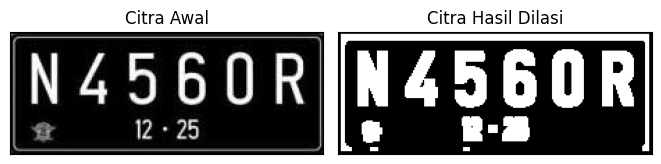

In [21]:
# 3. Fungsi Dilasi Manual & Pengujian pada Citra Plat Nomor
def dilasi_citra(F, w, SED=None):
    # Dimensi citra input
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Structuring Element default: matriks persegi 1 bernilai w x w
    if SED is None:
        SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi spasial
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

# Baca citra grayscale dan binarisasi
img_d = cv.imread(os.path.join(IMG_DIR, 'plat nomer.jpg'), 0)
ret, thresh = cv.threshold(img_d, 125, 200, cv.THRESH_BINARY)

w = 5
imgD = dilasi_citra(thresh, w)

# Visualisasi Citra Awal vs Hasil Dilasi
plt.figure(figsize=(10, 4))
plt.subplot(131)
plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(132)
plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()


### 4. Dilasi Citra Menggunakan Library OpenCV (`cv.dilate`)
Operasi dilasi menggunakan fungsi bawaan OpenCV `cv.dilate()` dengan Structuring Element berukuran $3 \times 3$.


Kernel SED:
[[1 1 1]
 [1 1 1]
 [1 1 1]]


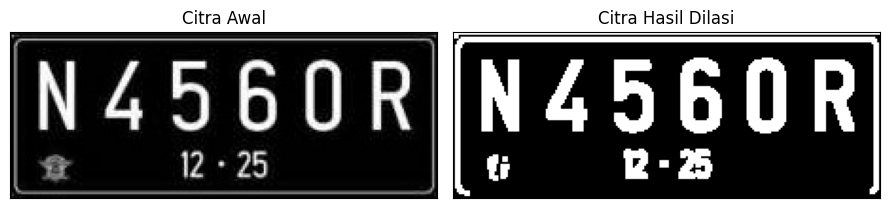

In [22]:
# 4. Dilasi Menggunakan cv.dilate() OpenCV
img = cv.imread(os.path.join(IMG_DIR, 'plat nomer.jpg'), 0)
ret, thresh = cv.threshold(img, 127, 225, cv.THRESH_BINARY)

# Kernel 3x3 Ones
kernel = np.ones((3, 3), np.uint8)
dilasi = cv.dilate(thresh, kernel, iterations=1)

print('Kernel SED:')
print(kernel)

plt.figure(figsize=(9, 4))
plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(122)
plt.imshow(dilasi, cmap='gray')
plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()


### 5. Erosi Citra Tanpa Library Morphology OpenCV
Membuat fungsi erosi manual tanpa pustaka OpenCV dengan Structuring Element Erosi (SE) berbentuk square $5 \times 5$.
Operasi erosi mengganti nilai piksel referensi dengan nilai minimum hasil perkalian tetangga citra dan structuring element:
$$I_{erosi}(i, j) = \min(F(i-c..i+c, j-c..j+c) \times SE)$$


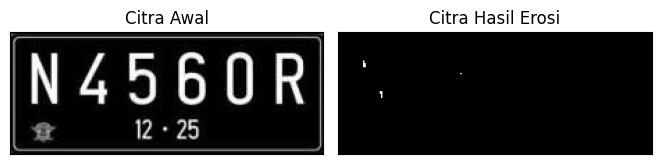

In [23]:
# 5. Fungsi Erosi Manual & Pengujian pada Citra Plat Nomor
def erosi_citra(F, k, SE=None):
    # Dimensi citra input
    m, n = F.shape

    # Generate structuring element default persegi k x k
    if SE is None:
        SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi spasial
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

img_e = cv.imread(os.path.join(IMG_DIR, 'plat nomer.jpg'), 0)
ret1, thresh1 = cv.threshold(img_e, 175, 225, cv.THRESH_BINARY)

k = 5
imgE = erosi_citra(thresh1, k)

plt.figure(figsize=(10, 4))
plt.subplot(131)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(132)
plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()


### 6. Erosi Citra Menggunakan Library OpenCV (`cv.erode`)
Operasi erosi menggunakan fungsi bawaan OpenCV `cv.erode()` dengan Structuring Element square $5 \times 5$.


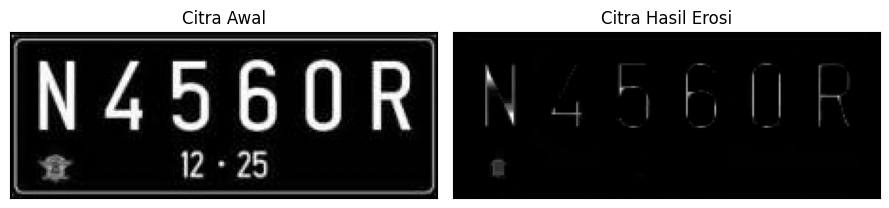

In [24]:
# 6. Erosi Menggunakan cv.erode() OpenCV
img = cv.imread(os.path.join(IMG_DIR, 'plat nomer.jpg'), 0)
kernel = np.ones((5, 5), np.uint8)
erosion = cv.erode(img, kernel, iterations=1)

plt.figure(figsize=(9, 4))
plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(122)
plt.imshow(erosion, cmap='gray')
plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()


### 7. Operasi Opening (Tanpa dan Dengan Library)
**Opening** adalah operasi erosi yang diikuti oleh dilasi:
$$A \circ B = (A \ominus B) \oplus B$$
Berfungsi menghilangkan noise/titik-titik putih di latar belakang luar objek tanpa mengubah ukuran keseluruhan objek secara drastis.


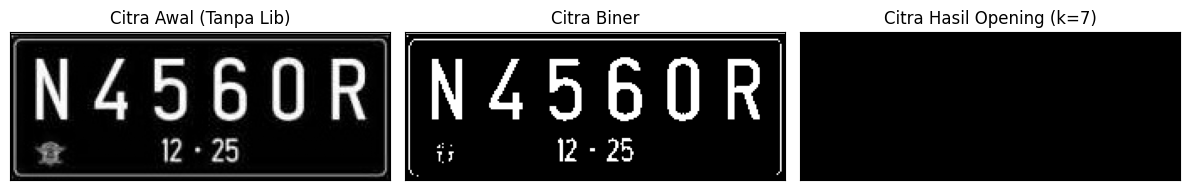

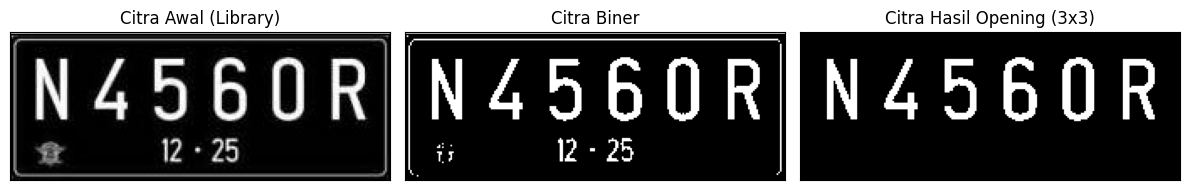

In [25]:
# 7. Operasi Opening Tanpa & Dengan Library Morphology

# A. Opening Tanpa Library Morphology (k=7)
img_o = cv.imread(os.path.join(IMG_DIR, 'plat nomer.jpg'), 0)
reto, thresho = cv.threshold(img_o, 127, 225, cv.THRESH_BINARY)
k = 7
imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.figure(figsize=(12, 4))
plt.subplot(131)
plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal (Tanpa Lib)')
plt.xticks([]), plt.yticks([])

plt.subplot(132)
plt.imshow(thresho, cmap='gray')
plt.title('Citra Biner')
plt.xticks([]), plt.yticks([])

plt.subplot(133)
plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening (k=7)')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

# B. Opening Menggunakan Library cv.morphologyEx (Kernel 3x3)
img = cv.imread(os.path.join(IMG_DIR, 'plat nomer.jpg'), 0)
ret, thresh = cv.threshold(img, 127, 225, cv.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
openn = cv.morphologyEx(thresh, cv.MORPH_OPEN, kernel)

plt.figure(figsize=(12, 4))
plt.subplot(131)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal (Library)')
plt.xticks([]), plt.yticks([])

plt.subplot(132)
plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner')
plt.xticks([]), plt.yticks([])

plt.subplot(133)
plt.imshow(openn, cmap='gray')
plt.title('Citra Hasil Opening (3x3)')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()


### 8. Operasi Closing (Tanpa dan Dengan Library)
**Closing** adalah operasi dilasi yang diikuti oleh erosi:
$$A \bullet B = (A \oplus B) \ominus B$$
Berfungsi untuk menutup lubang-lubang kecil atau retakan di dalam segmen objek serta menyatukan kontur tepi.


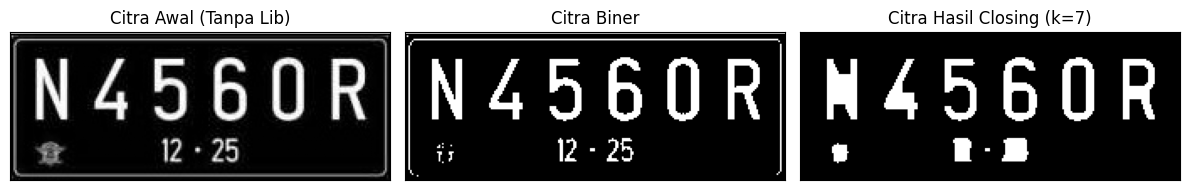

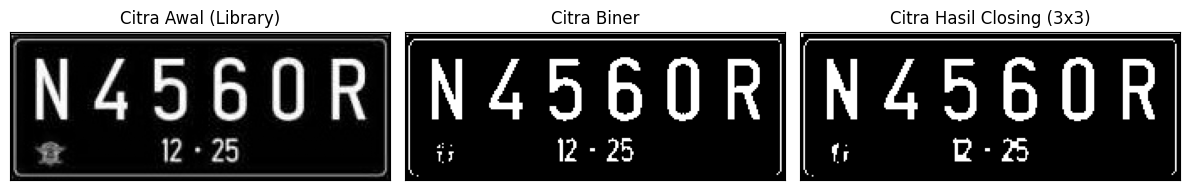

In [26]:
# 8. Operasi Closing Tanpa & Dengan Library Morphology

# A. Closing Tanpa Library (k=7)
img_c = cv.imread(os.path.join(IMG_DIR, 'plat nomer.jpg'), 0)
retc, threshc = cv.threshold(img_c, 127, 225, cv.THRESH_BINARY)
k = 7
imgC = erosi_citra(dilasi_citra(threshc, k), k)

plt.figure(figsize=(12, 4))
plt.subplot(131)
plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal (Tanpa Lib)')
plt.xticks([]), plt.yticks([])

plt.subplot(132)
plt.imshow(threshc, cmap='gray')
plt.title('Citra Biner')
plt.xticks([]), plt.yticks([])

plt.subplot(133)
plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing (k=7)')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

# B. Closing Menggunakan Library cv.morphologyEx (Kernel 3x3)
img = cv.imread(os.path.join(IMG_DIR, 'plat nomer.jpg'), 0)
ret, thresh = cv.threshold(img, 127, 225, cv.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
closs = cv.morphologyEx(thresh, cv.MORPH_CLOSE, kernel)

plt.figure(figsize=(12, 4))
plt.subplot(131)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal (Library)')
plt.xticks([]), plt.yticks([])

plt.subplot(132)
plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner')
plt.xticks([]), plt.yticks([])

plt.subplot(133)
plt.imshow(closs, cmap='gray')
plt.title('Citra Hasil Closing (3x3)')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()


### 9. Operasi Dilasi dengan Structuring Element Cross $3 \times 3$ dan $5 \times 5$
Menerapkan Structuring Element berbentuk tanda silang (Cross) berukuran $3 \times 3$ dan $5 \times 5$ pada fungsi dilasi manual:
- Cross 3x3:
$$\begin{bmatrix} 0 & 1 & 0 \\ 1 & 1 & 1 \\ 0 & 1 & 0 \end{bmatrix}$$
- Cross 5x5:
$$\begin{bmatrix} 0 & 0 & 1 & 0 & 0 \\ 0 & 0 & 1 & 0 & 0 \\ 1 & 1 & 1 & 1 & 1 \\ 0 & 0 & 1 & 0 & 0 \\ 0 & 0 & 1 & 0 & 0 \end{bmatrix}$$


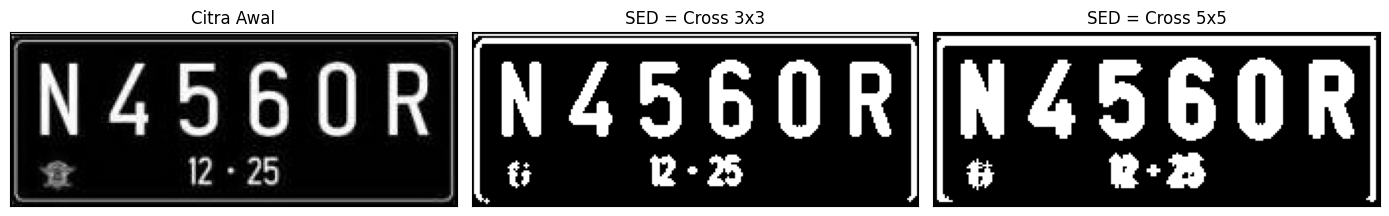

In [27]:
# 9. Dilasi dengan SED Berbentuk Cross 3x3 dan 5x5
img_d = cv.imread(os.path.join(IMG_DIR, 'plat nomer.jpg'), 0)
ret, thresh = cv.threshold(img_d, 127, 225, cv.THRESH_BINARY)

# 1. SED Cross 3x3
SED_cross3 = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
], dtype=np.uint8)
imgD_cross3 = dilasi_citra(thresh, 3, SED_cross3)

# 2. SED Cross 5x5
SED_cross5 = np.array([
    [0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0],
    [1, 1, 1, 1, 1],
    [0, 0, 1, 0, 0],
    [0, 0, 1, 0, 0]
], dtype=np.uint8)
imgD_cross5 = dilasi_citra(thresh, 5, SED_cross5)

# Visualisasi perbandingan
plt.figure(figsize=(14, 4))
plt.subplot(131)
plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(132)
plt.imshow(imgD_cross3, cmap='gray')
plt.title('SED = Cross 3x3')
plt.xticks([]), plt.yticks([])

plt.subplot(133)
plt.imshow(imgD_cross5, cmap='gray')
plt.title('SED = Cross 5x5')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()


### 10. Operasi Dilasi dengan Structuring Element Circular $3 \times 3$ dan $5 \times 5$
Menggunakan `cv.getStructuringElement(cv.MORPH_ELLIPSE, (w, w))` untuk membentuk elemen penstruktur melingkar (Circular/Disk).


SED Circle 3x3:
 [[0 1 0]
 [1 1 1]
 [0 1 0]]
SED Circle 5x5:
 [[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


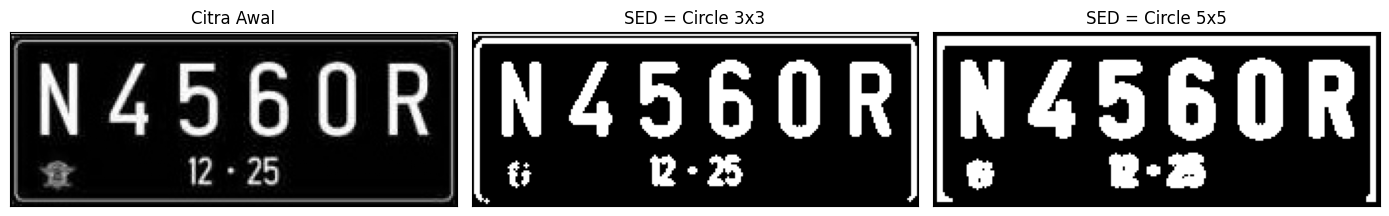

In [28]:
# 10. Dilasi dengan SED Circular 3x3 dan 5x5
img_d = cv.imread(os.path.join(IMG_DIR, 'plat nomer.jpg'), 0)
ret, thresh = cv.threshold(img_d, 127, 225, cv.THRESH_BINARY)

# SED Circular 3x3
SED_circle3 = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
imgD_circle3 = dilasi_citra(thresh, 3, SED_circle3)

# SED Circular 5x5
SED_circle5 = cv.getStructuringElement(cv.MORPH_ELLIPSE, (5, 5))
imgD_circle5 = dilasi_citra(thresh, 5, SED_circle5)

print('SED Circle 3x3:\n', SED_circle3)
print('SED Circle 5x5:\n', SED_circle5)

plt.figure(figsize=(14, 4))
plt.subplot(131)
plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(132)
plt.imshow(imgD_circle3, cmap='gray')
plt.title('SED = Circle 3x3')
plt.xticks([]), plt.yticks([])

plt.subplot(133)
plt.imshow(imgD_circle5, cmap='gray')
plt.title('SED = Circle 5x5')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()


### 11. Operasi Erosi dengan Structuring Element Rectangle $3 \times 5$ dan $5 \times 7$
Menggunakan Structuring Element berbentuk persegi panjang (Rectangle) yang dibuat dengan `cv.getStructuringElement(cv.MORPH_RECT, (p, l))`.


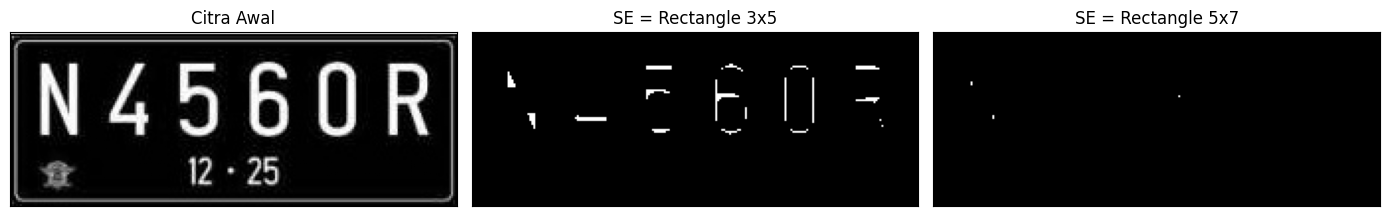

In [29]:
# 11. Erosi Citra dengan SE Rectangle 3x5 dan 5x7
def erosi_citra_rect(F, p, l):
    # Dimensi citra
    m, n = F.shape
    SE = cv.getStructuringElement(cv.MORPH_RECT, (p, l))
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i - constant1:i + constant1 + 1, j - constant2:j + constant2 + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

img_e = cv.imread(os.path.join(IMG_DIR, 'plat nomer.jpg'), 0)
ret1, thresh1 = cv.threshold(img_e, 127, 225, cv.THRESH_BINARY)

# SE Rectangle 3x5 (lebar p=5, tinggi l=3)
imgE_rect35 = erosi_citra_rect(thresh1, 5, 3)

# SE Rectangle 5x7 (lebar p=7, tinggi l=5)
imgE_rect57 = erosi_citra_rect(thresh1, 7, 5)

plt.figure(figsize=(14, 4))
plt.subplot(131)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(132)
plt.imshow(imgE_rect35, cmap='gray')
plt.title('SE = Rectangle 3x5')
plt.xticks([]), plt.yticks([])

plt.subplot(133)
plt.imshow(imgE_rect57, cmap='gray')
plt.title('SE = Rectangle 5x7')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()


### 12. Operasi Erosi dengan Structuring Element Line Vertikal $3$ dan $5$
Menggunakan Structuring Element berbentuk garis vertikal berukuran $(1, k)$ untuk mengikis objek searah vertikal.


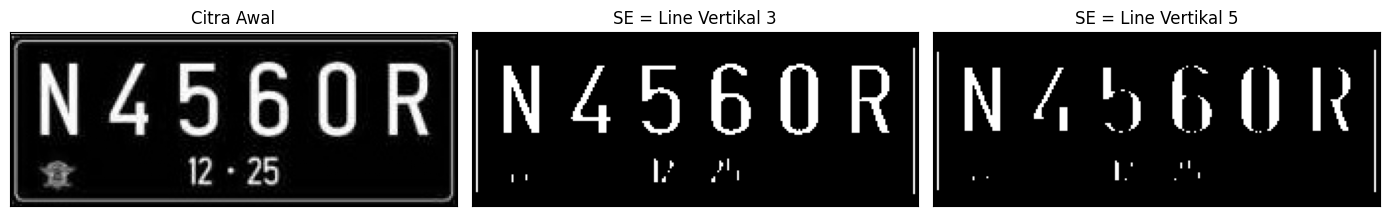

In [30]:
# 12. Erosi Citra dengan SE Line Vertikal
def erosi_line_vertikal(F, k):
    m, n = F.shape
    SE = cv.getStructuringElement(cv.MORPH_RECT, (1, k))
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant, m - constant):
        for j in range(n):
            temp = F[i - constant:i + constant + 1, j:j + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

img_e = cv.imread(os.path.join(IMG_DIR, 'plat nomer.jpg'), 0)
ret1, thresh1 = cv.threshold(img_e, 127, 225, cv.THRESH_BINARY)

imgE_line3 = erosi_line_vertikal(thresh1, 3)
imgE_line5 = erosi_line_vertikal(thresh1, 5)

plt.figure(figsize=(14, 4))
plt.subplot(131)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(132)
plt.imshow(imgE_line3, cmap='gray')
plt.title('SE = Line Vertikal 3')
plt.xticks([]), plt.yticks([])

plt.subplot(133)
plt.imshow(imgE_line5, cmap='gray')
plt.title('SE = Line Vertikal 5')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()


### 13. Transformasi Top-Hat (White-Hat)
**Top-Hat Transform** diperoleh dari selisih antara citra asli dengan hasil opening citra:
$$T_{hat}(f) = f - (f \circ b)$$
Operator ini mengekstrak dan menonjolkan fitur-fitur yang lebih terang daripada lingkungannya dan berukuran lebih kecil daripada structuring element.


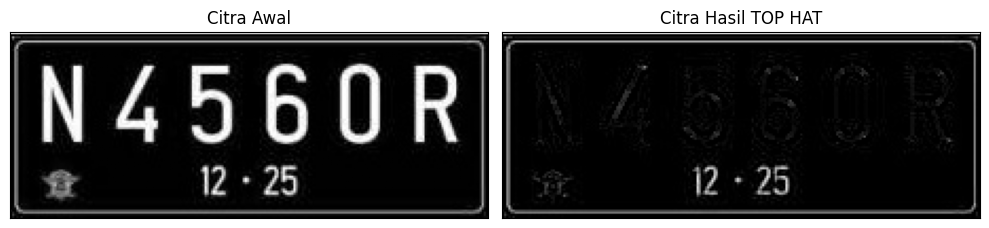

In [31]:
# 13. Transformasi Top-Hat Menggunakan OpenCV
img = cv.imread(os.path.join(IMG_DIR, 'plat nomer.jpg'))
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

filterSize = (3, 3)
kernel = cv.getStructuringElement(cv.MORPH_RECT, filterSize)
tophat_img = cv.morphologyEx(img_gray, cv.MORPH_TOPHAT, kernel)

plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.imshow(img_gray, cmap='gray')
plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(122)
plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()


### 14. Transformasi Black-Hat (Bottom-Hat)
**Black-Hat Transform** diperoleh dari selisih antara hasil closing citra dengan citra aslinya:
$$B_{hat}(f) = (f \bullet b) - f$$
Operator ini mengekstrak dan memperjelas fitur-fitur gelap yang berada di atas latar belakang yang lebih terang.


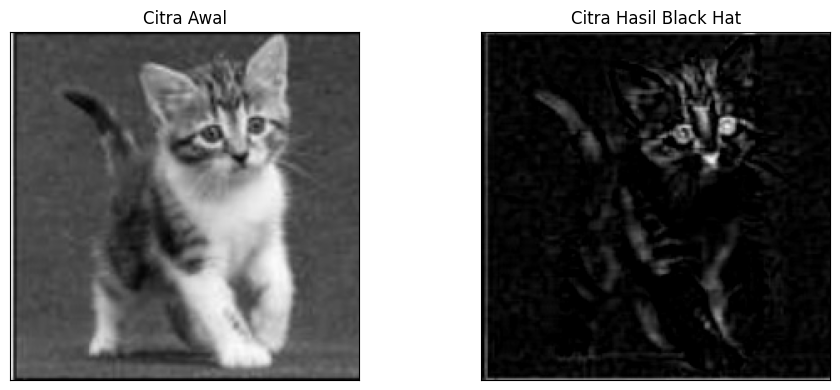

In [32]:
# 14. Transformasi Black-Hat pada Citra kitten01.jpg
img = cv.imread(os.path.join(IMG_DIR, 'kitten01.jpg'))
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

Kernel = cv.getStructuringElement(cv.MORPH_RECT, (13, 5))
blackhat = cv.morphologyEx(img_gray, cv.MORPH_BLACKHAT, Kernel)

plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.imshow(img_gray, cmap='gray')
plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(122)
plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()


### 15. Operasi Skeleton (Skeletonization)
Skeleton memberikan representasi rangka satu piksel dari suatu objek biner, sambil tetap mempertahankan struktur topologi dan konektivitas aslinya.
Menggunakan `skimage.morphology.skeletonize` pada citra `lily.jpg` yang dibinarisasi dengan threshold Triangle.


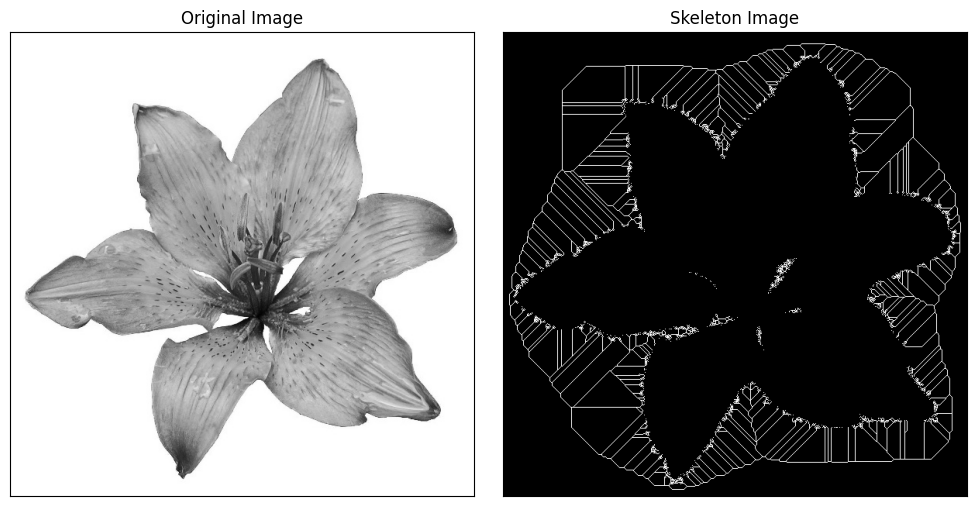

In [33]:
# 15. Skeleton Menggunakan skimage.morphology
img = cv.imread(os.path.join(IMG_DIR, 'lily.jpg'), 0)

# Binarisasi citra menggunakan Triangle thresholding
binary = img > filters.threshold_triangle(img)
binary_cp = binary.astype(np.uint8)

# Skeletonize
skeleton = skeletonize(binary_cp)

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.xticks([]), plt.yticks([])

plt.subplot(122)
plt.imshow(skeleton, cmap='gray')
plt.title('Skeleton Image')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()


### 16. Operasi Skeleton Inverse
Menampilkan skeleton pada latar belakang inversi warna (piksel gelap sebagai objek utama) dengan colormap `gray_r`.


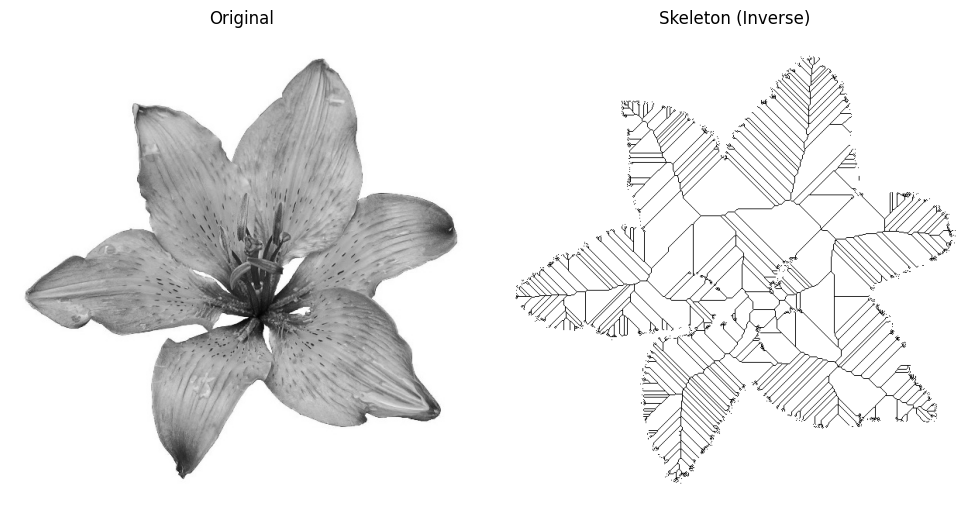

In [34]:
# 16. Skeleton Inverse
img = cv.imread(os.path.join(IMG_DIR, 'lily.jpg'), 0)

# Objek gelap sebagai True (< threshold)
binary_inv = img < filters.threshold_triangle(img)
skeleton_inv = skeletonize(binary_inv)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img, cmap='gray')
ax[0].set_title('Original')
ax[0].axis('off')

ax[1].imshow(skeleton_inv, cmap='gray_r')
ax[1].set_title('Skeleton (Inverse)')
ax[1].axis('off')
plt.tight_layout()
plt.show()


### 17. Thickening & Thinning
Perbandingan proses penipisan (*thinning*) dan *skeletonization* pada citra biner menggunakan pustaka `skimage.morphology`.


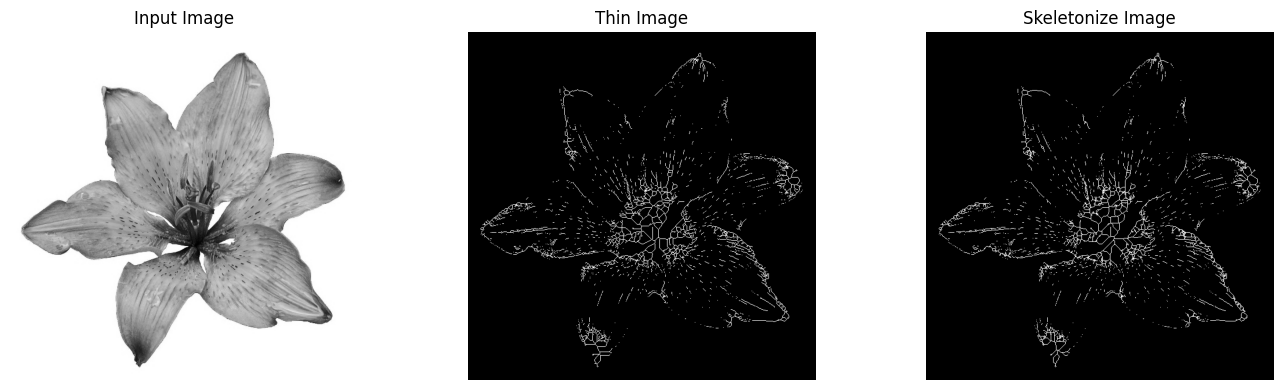

In [35]:
# 17. Thickening dan Thinning Menggunakan skimage
img_lily = io.imread(os.path.join(IMG_DIR, 'lily.jpg'))
if img_lily.ndim == 3:
    image = img_as_float(color.rgb2gray(img_lily))
else:
    image = img_as_float(img_lily)

image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(14, 4))
ax0.imshow(image, cmap='gray')
ax0.set_title('Input Image')
ax0.axis('off')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin Image')
ax1.axis('off')

ax2.imshow(out_skeletonize, cmap='gray')
ax2.set_title('Skeletonize Image')
ax2.axis('off')
plt.tight_layout()
plt.show()


---

## E. TUGAS PRAKTIKUM: Implementasi Morfologi pada Dataset KTP
**Deskripsi Tugas:**  
Tugas Praktikum Morfologi melibatkan implementasi dataset KTP yang terdapat dalam Modul 7 (`ktp_fulan.jpg` / `ktp.jpg`).
Tujuannya adalah menerapkan operasi morfologi (Opening, Closing, Dilasi, Erosi, Top-Hat) untuk:
1. Menghilangkan noise tekstur batik/background pada kartu KTP.
2. Memperbaiki dan menyambungkan kembali garis teks (NIK, Nama, Tempat/Tgl Lahir, dsb.) yang putus atau terpecah akibat binarisasi.
3. Membandingkan citra KTP sebelum dan sesudah penerapan teknik morfologi untuk meningkatkan keterbacaan (*readability*).


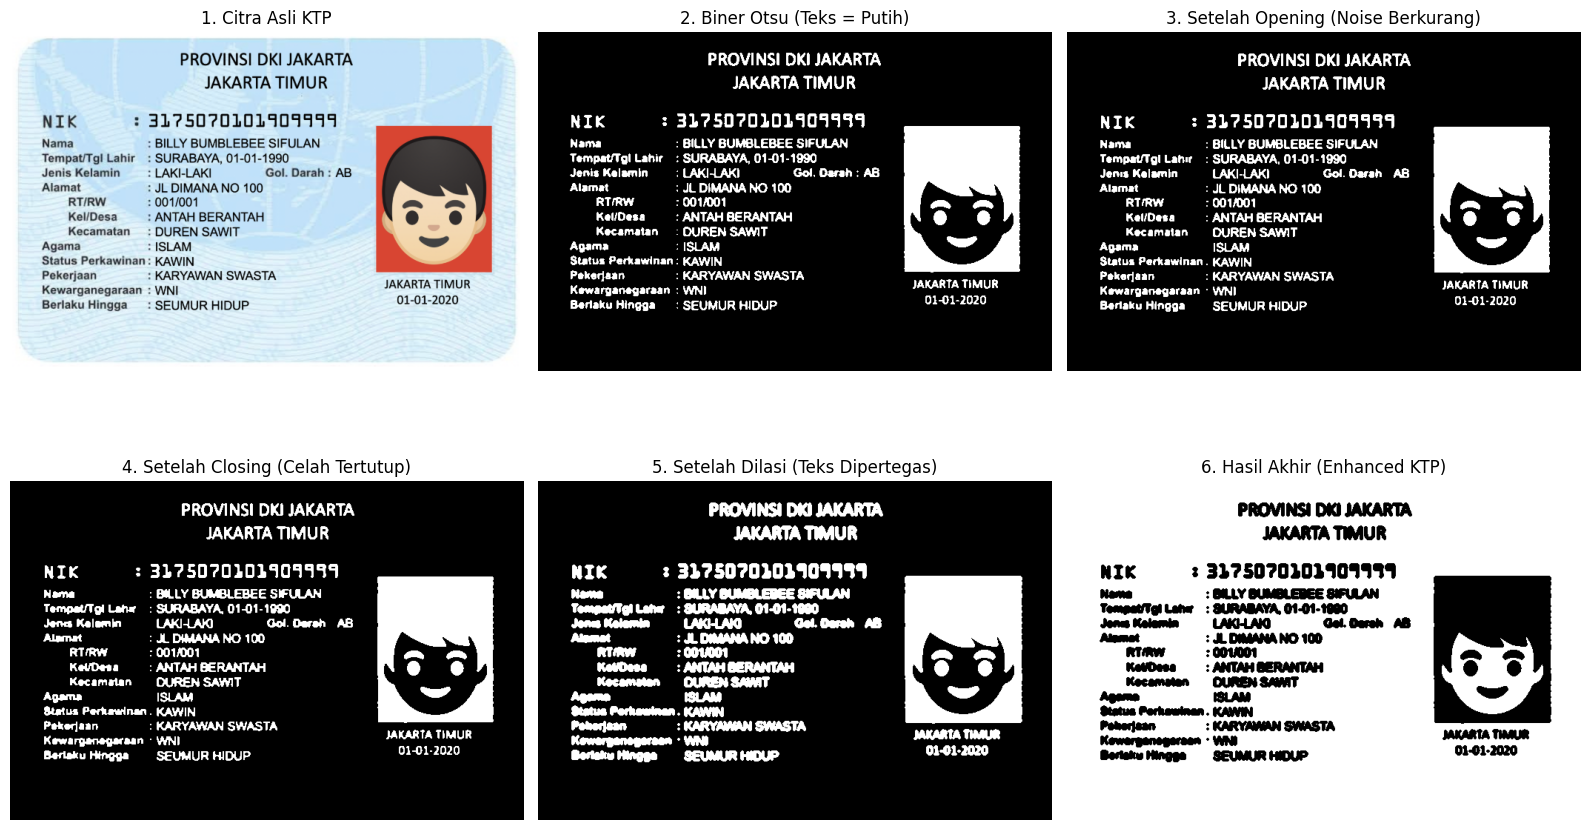

In [36]:
# E. Penerapan Operasi Morfologi pada Citra KTP
ktp_path = os.path.join(IMG_DIR, 'ktp_fulan.jpg')
if not os.path.exists(ktp_path):
    ktp_path = os.path.join(IMG_DIR, 'ktp.jpg')

ktp_bgr = cv.imread(ktp_path)
ktp_gray = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2GRAY)

# Step 1: Pra-pengolahan - Reduksi noise awal dengan Gaussian Blur
ktp_blur = cv.GaussianBlur(ktp_gray, (3, 3), 0)

# Step 2: Binarisasi menggunakan Otsu Thresholding
_, ktp_otsu = cv.threshold(ktp_blur, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)

# Step 3: Operasi Opening - Menghilangkan noise bintik kecil di luar huruf
se_open = cv.getStructuringElement(cv.MORPH_RECT, (2, 2))
ktp_opened = cv.morphologyEx(ktp_otsu, cv.MORPH_OPEN, se_open)

# Step 4: Operasi Closing - Menutup rongga dan celah pada karakter huruf/angka
se_close = cv.getStructuringElement(cv.MORPH_RECT, (2, 2))
ktp_closed = cv.morphologyEx(ktp_opened, cv.MORPH_CLOSE, se_close)

# Step 5: Dilasi ringan untuk menebalkan stroke karakter font
se_dilate = cv.getStructuringElement(cv.MORPH_CROSS, (3, 3))
ktp_enhanced = cv.dilate(ktp_closed, se_dilate, iterations=1)

# Inversi kembali ke background putih, teks hitam untuk keterbacaan standar OCR
ktp_final = cv.bitwise_not(ktp_enhanced)

# Visualisasi tahapan peningkatan kualitas citra KTP
plt.figure(figsize=(16, 10))
plt.subplot(2, 3, 1)
plt.imshow(cv.cvtColor(ktp_bgr, cv.COLOR_BGR2RGB))
plt.title('1. Citra Asli KTP')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(ktp_otsu, cmap='gray')
plt.title('2. Biner Otsu (Teks = Putih)')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(ktp_opened, cmap='gray')
plt.title('3. Setelah Opening (Noise Berkurang)')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(ktp_closed, cmap='gray')
plt.title('4. Setelah Closing (Celah Tertutup)')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(ktp_enhanced, cmap='gray')
plt.title('5. Setelah Dilasi (Teks Dipertegas)')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(ktp_final, cmap='gray')
plt.title('6. Hasil Akhir (Enhanced KTP)')
plt.axis('off')

plt.tight_layout()
plt.show()


### Analisis Hasil Penerapan Morfologi pada Citra KTP:
1. **Reduksi Noise:** Citra KTP asli memiliki latar belakang berupa pola/garis guilloche (batik sekuriti). Setelah binarisasi Otsu, pola tersebut meninggalkan noise titik-titik putih halus. Penerapan operasi **Opening** dengan kernel $2 \times 2$ berhasil mengikis dan melenyapkan bintik-bintik noise tanpa merusak struktur karakter teks utama.
2. **Rekonstruksi Karakter Teks:** Pada hasil binarisasi awal, beberapa huruf mengalami retakan atau garis putus akibat degradasi intensitas piksel. Operasi **Closing** berhasil menyambungkan kembali komponen huruf yang retak tersebut.
3. **Penebalan dan Keterbacaan:** Operasi **Dilasi** dengan elemen penstruktur Cross $3 \times 3$ mengembalikan ketebalan stroke tulisan NIK, Nama, dan alamat, sehingga karakter lebih solid dan kontras untuk proses pembacaan manusia maupun deteksi OCR lanjutan.
